# 5. Fine-tuning pretrained models

MobileNetV2 and SqueezeNet 1.1, pretrained on ImageNet, are fine-tuned on the same split, at the
same 64×64 resolution, through the same training loop as the custom models, and evaluated on the
same test images.

**Run time:** about 12 minutes on an NVIDIA T4 GPU.

**Writes:** for each run (`mobilenet_v2_adam`, `squeezenet1_1_adam`): `results/<run>/history.json`,
`test_metrics.json`, `curves.png` and `confusion_matrix.png`, and `checkpoints/<run>/best.pt`.

## Setup

Folders, the random seed, the device, and small helpers for files and figures. Every notebook in
this folder starts with the same setup.

In [1]:
import json
import os
import platform
import random
import re
import subprocess
import sys
from pathlib import Path

import numpy as np
import torch
import torchvision

# Everything is read from and written to folders next to this notebook.
DATA_DIR = Path("data")                # the downloaded dataset and a decoded-pixel cache
RESULTS_DIR = Path("results")          # metrics, figures and tables
CHECKPOINT_DIR = Path("checkpoints")   # trained weights

SEED = 42            # fixes the split, the initial weights, augmentation and batch order
NUM_CLASSES = 10     # EuroSAT land-cover classes
INPUT_SHAPE = (3, 64, 64)

# cuBLAS needs this workspace setting for repeatable matrix products on a GPU.
CUBLAS_WORKSPACE = ":4096:8"


def seed_everything(seed, deterministic=True):
    """Seed Python, NumPy and PyTorch, so a run gives the same numbers every time.

    With ``deterministic=True``, cuDNN uses deterministic algorithms and stops
    auto-tuning, and PyTorch prefers deterministic implementations. This costs a
    little speed. Without it, two runs of the same experiment can differ by a few
    tenths of a percent, the same size as some differences between the models.
    A few GPU operations have no deterministic version; PyTorch then warns
    instead of stopping.
    """
    if deterministic:
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", CUBLAS_WORKSPACE)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # seeds the CPU and every GPU
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic
    torch.use_deterministic_algorithms(deterministic, warn_only=True)


def cpu_name():
    """The processor's model name, or an empty string if the operating system won't say."""
    name = ""
    try:
        if sys.platform == "win32":
            import winreg

            key = winreg.OpenKey(
                winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0"
            )
            name = str(winreg.QueryValueEx(key, "ProcessorNameString")[0])
        elif sys.platform.startswith("linux"):
            with open("/proc/cpuinfo", encoding="utf-8") as handle:
                for line in handle:
                    if line.lower().startswith("model name"):
                        name = line.split(":", 1)[1]
                        break
        elif sys.platform == "darwin":
            name = subprocess.run(
                ["sysctl", "-n", "machdep.cpu.brand_string"],
                capture_output=True, text=True, timeout=5, check=False,
            ).stdout
    except Exception:
        name = ""
    name = name or platform.processor() or ""
    name = re.sub(r"\((R|TM|C)\)", "", name, flags=re.IGNORECASE)  # trademark signs
    return " ".join(name.split())


def describe_device(device):
    """A readable name for a device, such as ``cuda:0 (Tesla T4)``.

    Every timing is recorded together with this name: a time means little
    without the hardware it was measured on.
    """
    device = torch.device(device)
    if device.type == "cuda":
        index = device.index if device.index is not None else torch.cuda.current_device()
        return f"cuda:{index} ({torch.cuda.get_device_name(index)})"
    name = cpu_name()
    return f"cpu ({name})" if name else "cpu"


#: Model name -> function building it; filled in by the model definitions below.
MODEL_BUILDERS = {}


def build_model(name, num_classes=NUM_CLASSES):
    """Seed PyTorch, then build ``name``: the same seed always gives the same initial weights.

    The three optimizer runs rely on this to start from identical weights, so
    that their comparison measures the optimizer and not the initialisation.
    """
    torch.manual_seed(SEED)
    return MODEL_BUILDERS[name](num_classes)


def count_parameters(model, trainable_only=True):
    """Number of parameters; frozen ones are left out when ``trainable_only``."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def model_size_kb(model):
    """Size of the saved weights (``state_dict``) in KB, where 1 KB = 1,024 bytes.

    Saving the weights, as a device would store them, rather than counting 4
    bytes per parameter, also counts buffers such as batch-norm statistics.
    """
    import io

    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / 1024


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python       {platform.python_version()} ({platform.system()})")
print(f"PyTorch      {torch.__version__}")
print(f"torchvision  {torchvision.__version__}")
print(f"NumPy        {np.__version__}")
print(f"Device       {describe_device(DEVICE)}")

Python       3.13.15 (Linux)
PyTorch      2.11.0+cu130
torchvision  0.26.0+cu130
NumPy        2.1.3
Device       cuda:0 (Tesla T4)


Figures are shown inline at a small size and saved at print quality. Each model and each optimizer
keeps one colour and one name in every figure and table.

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 100,            # inline figures: small, so the notebook stays light
    "savefig.dpi": 200,           # saved figures: print quality
    "savefig.bbox": "tight",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.8,
})

MODEL_LABELS = {
    "model_a": "Model A",
    "model_b": "Model B",
    "mobilenet_v2": "MobileNetV2",
    "squeezenet1_1": "SqueezeNet 1.1",
}
MODEL_COLORS = {
    "model_a": "#4C72B0",
    "model_b": "#DD8452",
    "mobilenet_v2": "#55A868",
    "squeezenet1_1": "#C44E52",
}
OPTIMIZER_LABELS = {"sgd": "SGD", "sgd_momentum": "SGD + momentum", "adam": "Adam"}
OPTIMIZER_COLORS = {"sgd": "#8172B3", "sgd_momentum": "#937860", "adam": "#DA8BC3"}


def save_figure(fig, path):
    """Save a figure as a PNG, creating its folder if needed."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")

Results are saved as JSON and Markdown, so the tables can be rebuilt without retraining.

In [3]:
def write_json(path, payload):
    """Write ``payload`` as indented JSON, creating the folder if needed."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2) + "\n", encoding="utf-8", newline="\n")


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def write_text(path, text):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding="utf-8", newline="\n")


def format_cell(value, spec=None):
    """One table cell: thousands separators for whole numbers, ``spec`` for decimals."""
    if value is None:
        return "-"
    if isinstance(value, bool):
        return str(value)
    if spec is not None and isinstance(value, (int, float)):
        return format(value, spec)
    if isinstance(value, int):
        return f"{value:,}"
    if isinstance(value, float):
        return f"{value:,.1f}" if abs(value) >= 1000 else f"{value:.4g}"
    return str(value).replace("|", "\\|")


def markdown_table(headers, rows, caption=None, formats=None):
    """A Markdown table. Number columns are right-aligned; ``formats`` fixes their decimals."""
    formats = formats or [None] * len(headers)

    def numeric(column):
        cells = [row[column] for row in rows if row[column] is not None]
        return bool(cells) and all(
            isinstance(cell, (int, float)) and not isinstance(cell, bool) for cell in cells
        )

    lines = [f"*{caption}*", ""] if caption else []
    lines.append("| " + " | ".join(headers) + " |")
    lines.append("|" + "|".join("---:" if numeric(c) else "---" for c in range(len(headers))) + "|")
    for row in rows:
        lines.append("| " + " | ".join(format_cell(v, s) for v, s in zip(row, formats)) + " |")
    return "\n".join(lines) + "\n"

## Data

EuroSAT (Helber et al., 2019): 27,000 Sentinel-2 satellite images of 64×64 pixels, in 10 land-cover
classes. It is downloaded through torchvision and split 70 / 15 / 15 into training, validation and
test sets, stratified by class.

The split is drawn from a fixed seed with NumPy's legacy `RandomState`, whose random sequence does not
change between NumPy versions, so every machine draws the same split. A SHA-256 fingerprint of the
split list (each image's path, label and split) is checked against the fingerprint of the split used
for the reported results: if the dataset or the code differed, the check stops the notebook.

In [4]:
import csv
import hashlib
import io
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass

from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

SPLIT_NAMES = ("train", "val", "test")
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
IMAGE_SIZE = (64, 64)
EXPECTED_IMAGES = 27_000
BATCH_SIZE = 64

# SHA-256 of the split behind every reported result (see split_fingerprint below).
EXPECTED_SPLIT_SHA256 = "9fc7491cc0b8266013ca7f91e4a0988f39464988545251ee1361552823ea162b"


def download_eurosat():
    """Download EuroSAT through torchvision (about 94 MB, only once) and list its images.

    Returns:
        The class names, in label order (torchvision sorts the folder names), and
        one row per image, sorted by its path inside the dataset, such as
        ``AnnualCrop/AnnualCrop_1.jpg``.
    """
    dataset = torchvision.datasets.EuroSAT(root=str(DATA_DIR), download=True)
    classes = list(dataset.classes)
    rows = [
        {
            "relative_path": f"{classes[label]}/{Path(path).name}",
            "label_index": int(label),
            "label_name": classes[label],
            "source": Path(path),
        }
        for path, label in dataset.samples
    ]
    rows.sort(key=lambda row: row["relative_path"])
    if len(classes) != NUM_CLASSES or len(rows) != EXPECTED_IMAGES:
        raise RuntimeError(
            f"found {len(classes)} classes and {len(rows)} images, expected {NUM_CLASSES} and "
            f"{EXPECTED_IMAGES}: the download is incomplete. Delete {DATA_DIR / 'eurosat'} and run again."
        )
    return classes, rows


def split_sizes(n, fractions):
    """Train, validation and test sizes for one class of ``n`` images."""
    sizes = [round(n * fractions["train"]), round(n * fractions["val"])]
    sizes.append(n - sum(sizes))
    if n >= 3:  # move images from train so that no split is empty
        for index in (1, 2):
            if sizes[index] < 1:
                sizes[0] -= 1 - sizes[index]
                sizes[index] = 1
    return sizes


def stratified_split(labels, fractions, seed):
    """Assign every image to ``train``, ``val`` or ``test``, class by class.

    Within each class the images are shuffled, then cut in the given proportions.
    Splitting per class keeps the class balance identical in all three splits.

    Returns:
        The split name of each image, in the order of ``labels``.
    """
    labels = np.asarray(labels)
    assignment = np.empty(len(labels), dtype=object)
    rng = np.random.RandomState(seed)
    for label in np.unique(labels):  # sorted, so the random sequence is fixed
        members = rng.permutation(np.flatnonzero(labels == label))
        start = 0
        for name, count in zip(SPLIT_NAMES, split_sizes(len(members), fractions)):
            assignment[members[start : start + count]] = name
            start += count
    return assignment.tolist()


def split_fingerprint(rows):
    """SHA-256 of the split list, written as a CSV of path, label index, label name and split."""
    buffer = io.StringIO(newline="")
    writer = csv.writer(buffer, lineterminator="\n")
    writer.writerow(["relative_path", "label_index", "label_name", "split"])
    for row in rows:
        writer.writerow([row["relative_path"], row["label_index"], row["label_name"], row["split"]])
    return hashlib.sha256(buffer.getvalue().encode("utf-8")).hexdigest()


def load_pixels(rows, cache_path):
    """Every image as one ``(N, 64, 64, 3)`` ``uint8`` array, in row order.

    Decoding a JPEG is a fixed step with nothing to learn, so it is done once and
    the pixels are cached next to the dataset. Augmentation and normalisation are
    still applied fresh in every epoch, on top of these pixels.
    """
    height, width = IMAGE_SIZE
    if cache_path.exists():
        pixels = np.load(cache_path)
        if pixels.shape == (len(rows), height, width, 3):
            return pixels

    pixels = np.empty((len(rows), height, width, 3), dtype=np.uint8)

    def decode(position):
        with Image.open(rows[position]["source"]) as image:
            array = np.asarray(image.convert("RGB"))
        if array.shape != (height, width, 3):
            raise ValueError(f"{rows[position]['relative_path']} is not {width}x{height}")
        pixels[position] = array

    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 1)) as pool:
        list(pool.map(decode, range(len(rows))))
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    np.save(cache_path, pixels)
    return pixels


def channel_stats(pixels, indices, chunk=1024):
    """Per-channel mean and standard deviation of the selected images, on a 0 to 1 scale.

    Computed in chunks with 64-bit sums, so the whole training set never needs
    more than a few tens of MB of extra memory.
    """
    indices = np.asarray(indices)
    total = np.zeros(3, dtype=np.float64)
    total_sq = np.zeros(3, dtype=np.float64)
    for start in range(0, len(indices), chunk):
        block = pixels[indices[start : start + chunk]].astype(np.float64) / 255.0
        total += block.sum(axis=(0, 1, 2))
        total_sq += np.square(block).sum(axis=(0, 1, 2))
    count = len(indices) * pixels.shape[1] * pixels.shape[2]
    mean = total / count
    std = np.sqrt(np.maximum(total_sq / count - np.square(mean), 0.0))
    return mean.tolist(), std.tolist()


@dataclass
class EuroSATData:
    """The prepared dataset: images, labels, the split and the normalisation statistics."""

    class_names: list
    rows: list
    labels: np.ndarray
    splits: dict          # split name -> indices into ``pixels``
    pixels: np.ndarray
    norm_mean: list       # of the training images only
    norm_std: list
    fingerprint: str


def prepare_data():
    """Download EuroSAT, draw the split, check its fingerprint and decode the images.

    The normalisation statistics come from the training images only: including
    validation or test images would leak held-out information into training.
    """
    classes, rows = download_eurosat()
    labels = [row["label_index"] for row in rows]
    for row, split in zip(rows, stratified_split(labels, SPLIT_FRACTIONS, SEED)):
        row["split"] = split

    fingerprint = split_fingerprint(rows)
    if fingerprint != EXPECTED_SPLIT_SHA256:
        raise RuntimeError(
            f"the split's fingerprint is {fingerprint[:16]}, not {EXPECTED_SPLIT_SHA256[:16]}: "
            "this is not the split behind the reported results"
        )

    pixels = load_pixels(rows, DATA_DIR / f"eurosat_pixels_{fingerprint[:16]}.npy")
    split_of = np.array([row["split"] for row in rows])
    splits = {name: np.flatnonzero(split_of == name) for name in SPLIT_NAMES}
    mean, std = channel_stats(pixels, splits["train"])
    return EuroSATData(
        class_names=classes,
        rows=rows,
        labels=np.array(labels, dtype=np.int64),
        splits=splits,
        pixels=pixels,
        norm_mean=mean,
        norm_std=std,
        fingerprint=fingerprint,
    )

Training images get random flips and quarter turns in every epoch. Satellite images have no natural
"up", so a flipped or rotated image is still a valid example. Validation and test images are never
augmented, so they are identical every time a model is evaluated.

In [5]:
class RandomRot90:
    """Rotate an image by 0, 90, 180 or 270 degrees, chosen at random.

    A quarter turn of a square image loses no pixels, unlike an arbitrary angle.
    """

    def __call__(self, image):
        quarter_turns = int(torch.randint(0, 4, (1,)).item())
        return torch.rot90(image, quarter_turns, dims=(-2, -1))

    def __repr__(self):
        return "RandomRot90()"


def build_transform(split, mean, std):
    """Augmentation for the training split only, then scaling to 0 to 1 and normalisation."""
    steps = []
    if split == "train":
        steps += [v2.RandomHorizontalFlip(p=0.5), v2.RandomVerticalFlip(p=0.5), RandomRot90()]
    steps += [v2.ToDtype(torch.float32, scale=True), v2.Normalize(mean=list(mean), std=list(std))]
    return v2.Compose(steps)


class PixelDataset(Dataset):
    """Images from the decoded-pixel array, returned as ``(normalised tensor, label)``."""

    def __init__(self, pixels, indices, labels, transform):
        self.pixels = pixels
        self.indices = np.asarray(indices, dtype=np.int64)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        image = torch.from_numpy(self.pixels[self.indices[item]]).permute(2, 0, 1)  # HWC to CHW
        return self.transform(image), int(self.labels[item])


def make_loaders(data, mean, std):
    """Training, validation and test DataLoaders, normalised with ``mean`` and ``std``.

    The training loader reshuffles in every epoch, with its own generator seeded
    from ``SEED``; validation and test keep a fixed order.
    """
    loaders = {}
    for split in SPLIT_NAMES:
        indices = data.splits[split]
        dataset = PixelDataset(
            data.pixels, indices, data.labels[indices], build_transform(split, mean, std)
        )
        is_train = split == "train"
        loaders[split] = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=is_train,
            generator=torch.Generator().manual_seed(SEED) if is_train else None,
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
            drop_last=False,
        )
    return loaders

## The pretrained models

MobileNetV2 (Sandler et al., 2018) and SqueezeNet 1.1 (Iandola et al., 2016) come with weights
trained on ImageNet. They reach efficiency in two different ways: MobileNetV2 uses inverted
residual blocks built from depthwise-separable convolutions, while SqueezeNet's fire modules first
"squeeze" the channels with 1×1 convolutions, then expand them again.

Fine-tuning strategy, the same for both:

- the ImageNet classifier is replaced by a new 10-class layer, initialised with small random weights;
- only the new classifier and the last few feature blocks are trained (3 blocks of MobileNetV2,
  2 fire modules of SqueezeNet); the earlier blocks keep their ImageNet features frozen;
- the trained feature blocks learn at a tenth of the classifier's learning rate, so the pretrained
  features are adjusted gently rather than overwritten.

Both models are fed the same 64×64 images as the custom models, not upsampled to their native
224×224. This keeps the cost comparison honest, at the resolution the sensor actually produces,
but it handicaps them: MobileNetV2's total stride of 32 leaves a 2×2 feature map. Their inputs are
normalised with the ImageNet statistics their weights were trained with.

In [6]:
from torch import nn
from torchvision.models import (
    MobileNet_V2_Weights,
    SqueezeNet1_1_Weights,
    mobilenet_v2,
    squeezenet1_1,
)

# Keep the downloaded ImageNet weights inside this folder, with the dataset.
torch.hub.set_dir(str(DATA_DIR / "torch_hub"))

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

PRETRAINED_SETTINGS = {
    "mobilenet_v2": {"unfreeze_last_n": 3, "dropout": 0.2, "backbone_lr_scale": 0.1},
    "squeezenet1_1": {"unfreeze_last_n": 2, "dropout": 0.5, "backbone_lr_scale": 0.1},
}


def replace_classifier(model, num_classes, dropout):
    """Swap the 1000-class ImageNet output layer for a ``num_classes`` one.

    MobileNetV2 ends in a linear layer; SqueezeNet in a 1x1 convolution followed
    by global average pooling. The new layer starts from small random weights
    (standard deviation 0.01) and zero biases.
    """
    old_head = model.classifier[1]
    model.classifier[0] = nn.Dropout(p=dropout)
    if isinstance(old_head, nn.Linear):          # MobileNetV2
        new_head = nn.Linear(old_head.in_features, num_classes)
    else:                                        # SqueezeNet
        new_head = nn.Conv2d(old_head.in_channels, num_classes, kernel_size=1)
    nn.init.normal_(new_head.weight, mean=0.0, std=0.01)
    nn.init.zeros_(new_head.bias)
    model.classifier[1] = new_head
    model.num_classes = num_classes
    return model


def unfreeze_last_blocks(model, count):
    """Freeze every weight, then unfreeze the classifier and the last ``count`` feature blocks."""
    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True
    for block in list(model.features.children())[-count:]:
        for parameter in block.parameters():
            parameter.requires_grad = True
    return model


def build_mobilenet_v2(num_classes=NUM_CLASSES):
    settings = PRETRAINED_SETTINGS["mobilenet_v2"]
    model = mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
    replace_classifier(model, num_classes, settings["dropout"])
    return unfreeze_last_blocks(model, settings["unfreeze_last_n"])


def build_squeezenet1_1(num_classes=NUM_CLASSES):
    settings = PRETRAINED_SETTINGS["squeezenet1_1"]
    model = squeezenet1_1(weights=SqueezeNet1_1_Weights.IMAGENET1K_V1)
    replace_classifier(model, num_classes, settings["dropout"])
    return unfreeze_last_blocks(model, settings["unfreeze_last_n"])


MODEL_BUILDERS["mobilenet_v2"] = build_mobilenet_v2
MODEL_BUILDERS["squeezenet1_1"] = build_squeezenet1_1

## Training

One training loop serves all four models, so their training times and accuracies are measured the
same way. Settings shared by every run:

- **30 epochs**, cross-entropy loss, batch size 64;
- **cosine annealing** of the learning rate, from the optimizer's rate down to 0.00001;
- **early stopping** on validation accuracy with a patience of 8 epochs, never before epoch 20;
- the **checkpoint with the best validation accuracy** is the one evaluated on the test set.

The test split is never used during training; model selection uses the validation split only.
Each epoch's time covers the training pass and the validation pass, and on a GPU the clock stops
only after all queued GPU work has finished.

In [7]:
import time

from torch import nn

EPOCHS = 30
MIN_LR = 1e-5           # floor of the cosine learning-rate schedule
EARLY_STOP_PATIENCE = 8
MIN_EPOCHS = 20

OPTIMIZER_SETTINGS = {
    "sgd": {"lr": 0.01, "momentum": 0.0, "weight_decay": 1e-4},
    "sgd_momentum": {"lr": 0.01, "momentum": 0.9, "weight_decay": 1e-4},
    "adam": {"lr": 0.001, "betas": (0.9, 0.999), "weight_decay": 1e-4},
}


def param_groups(model, base_lr, backbone_lr_scale):
    """Two optimizer groups for a pretrained model: its trainable feature blocks at a lower
    rate, its new classifier at ``base_lr``."""
    head = [p for p in model.classifier.parameters() if p.requires_grad]
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    return [
        {"params": backbone, "lr": base_lr * backbone_lr_scale, "name": "backbone"},
        {"params": head, "lr": base_lr, "name": "head"},
    ]


def build_optimizer(model, name, backbone_lr_scale=None):
    """The optimizer ``name`` over the model's trainable parameters.

    For a pretrained model, ``backbone_lr_scale`` puts the trainable feature
    blocks in their own group at a fraction of the learning rate.
    """
    settings = OPTIMIZER_SETTINGS[name]
    lr = settings["lr"]
    if backbone_lr_scale is None:
        params = [p for p in model.parameters() if p.requires_grad]
    else:
        params = param_groups(model, lr, backbone_lr_scale)
    if name in ("sgd", "sgd_momentum"):
        return torch.optim.SGD(params, lr=lr, momentum=settings["momentum"],
                               weight_decay=settings["weight_decay"], dampening=0.0, nesterov=False)
    return torch.optim.Adam(params, lr=lr, betas=settings["betas"], eps=1e-8,
                            weight_decay=settings["weight_decay"], amsgrad=False)


class EarlyStopping:
    """Stop when validation accuracy has not improved for ``patience`` epochs, never before ``min_epochs``."""

    def __init__(self, patience=EARLY_STOP_PATIENCE, min_epochs=MIN_EPOCHS):
        self.patience = patience
        self.min_epochs = min_epochs
        self.best = None
        self.bad_epochs = 0

    def step(self, val_acc, epoch):
        """Record one epoch; return True when training should stop."""
        if self.best is None or val_acc > self.best:
            self.best = val_acc
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return epoch >= self.min_epochs and self.bad_epochs >= self.patience


def train_one_epoch(model, loader, optimizer, criterion):
    """One pass over the training split. Returns ``(mean loss, accuracy)``."""
    model.train()
    total_loss, correct, seen = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("the training loss is not a finite number")
        loss.backward()
        optimizer.step()
        total_loss += float(loss.detach().item()) * int(labels.shape[0])
        correct += int((logits.argmax(dim=1) == labels).sum().item())
        seen += int(labels.shape[0])
    return total_loss / seen, correct / seen


def validate(model, loader, criterion):
    """Loss and accuracy on the validation split, without gradients."""
    model.eval()
    total_loss, correct, seen = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += float(loss.item()) * int(labels.shape[0])
            correct += int((logits.argmax(dim=1) == labels).sum().item())
            seen += int(labels.shape[0])
    return total_loss / seen, correct / seen


def train(model, model_name, optimizer_name, run_name, loaders, backbone_lr_scale=None):
    """Train one model and save its history and its best checkpoint.

    Reseeds first: the initial weights were seeded when the model was built, and
    this fixes dropout and augmentation, so the result does not depend on which
    cells ran before.

    Returns:
        The training history, also saved as ``results/<run_name>/history.json``.
    """
    seed_everything(SEED)
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = build_optimizer(model, optimizer_name, backbone_lr_scale)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=MIN_LR)
    stopper = EarlyStopping()
    checkpoint = CHECKPOINT_DIR / run_name / "best.pt"
    checkpoint.parent.mkdir(parents=True, exist_ok=True)

    epochs, best_val_acc, best_epoch, total_time = [], None, None, 0.0
    for epoch in range(1, EPOCHS + 1):
        started = time.perf_counter()
        train_loss, train_acc = train_one_epoch(model, loaders["train"], optimizer, criterion)
        val_loss, val_acc = validate(model, loaders["val"], criterion)
        scheduler.step()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)  # GPU work is asynchronous: wait before reading the clock
        epoch_time = time.perf_counter() - started
        total_time += epoch_time
        epochs.append({
            "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
            "train_acc": train_acc, "val_acc": val_acc,
            "lr": max(float(group["lr"]) for group in optimizer.param_groups),
            "epoch_time_s": epoch_time,
        })

        improved = best_val_acc is None or val_acc > best_val_acc
        if improved:
            best_val_acc, best_epoch = val_acc, epoch
            torch.save({"model": model_name, "epoch": epoch, "val_acc": val_acc,
                        "state_dict": model.state_dict()}, checkpoint)
        print(f"epoch {epoch:2d}/{EPOCHS}  train loss {train_loss:.4f}  acc {train_acc:.4f}  |  "
              f"val loss {val_loss:.4f}  acc {val_acc:.4f}  |  {epoch_time:5.1f} s"
              + ("  best" if improved else ""))
        if stopper.step(val_acc, epoch):
            print(f"Early stop: no improvement for {stopper.patience} epochs.")
            break

    settings = {key: list(value) if isinstance(value, tuple) else value
                for key, value in OPTIMIZER_SETTINGS[optimizer_name].items()}
    history = {
        "run": run_name,
        "model": model_name,
        "optimizer": optimizer_name,
        "seed": SEED,
        "device": describe_device(DEVICE),
        "epochs": epochs,
        "best_epoch": best_epoch,
        "best_val_acc": best_val_acc,
        "total_train_time_s": total_time,
        "hyperparameters": {
            **settings,
            "backbone_lr_scale": backbone_lr_scale,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "scheduler": f"cosine, min lr {MIN_LR}",
            "augmentation": "random horizontal flip, vertical flip, quarter turn (training only)",
        },
    }
    write_json(RESULTS_DIR / run_name / "history.json", history)
    print(f"Best validation accuracy {best_val_acc:.4f} at epoch {best_epoch}; "
          f"{total_time / len(epochs):.1f} s per epoch on {describe_device(DEVICE)}")
    return history

## Evaluation

Every model is scored on the test split by the same functions, right after training, from its best
checkpoint:

- **accuracy**, and **macro-averaged precision, recall and F1**: every class counts equally.
  Micro-averaged precision would equal the accuracy for single-label classification;
- a class that is never predicted gets precision 0 rather than an error;
- the **confusion matrix** counts, in row `i` and column `j`, the test images of true class `i`
  predicted as class `j`. Its figure is normalised by true class, so the diagonal reads as
  per-class recall.

In [8]:
import textwrap

from sklearn.metrics import confusion_matrix, precision_recall_fscore_support


def predict(model, loader):
    """True and predicted classes for every image of ``loader``, in its order."""
    model.eval()
    truths, predictions = [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(DEVICE, non_blocking=True))
            predictions.append(logits.argmax(dim=1).cpu())
            truths.append(torch.as_tensor(labels).cpu())
    return torch.cat(truths).numpy(), torch.cat(predictions).numpy()


def compute_metrics(y_true, y_pred, class_names):
    """Accuracy, macro and weighted precision / recall, per-class scores and the confusion matrix."""
    labels = list(range(len(class_names)))  # explicit, so a class that is never predicted keeps its row
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average=None, zero_division=0
    )
    per_class = {
        name: {"precision": float(precision[i]), "recall": float(recall[i]),
               "f1": float(f1[i]), "support": int(support[i])}
        for i, name in enumerate(class_names)
    }
    total = int(support.sum())

    def weighted(key):  # each class's score weighted by its number of test images
        value = sum(scores[key] * scores["support"] for scores in per_class.values()) / total
        return min(1.0, value)  # guards a rounding error just above 1

    return {
        "accuracy": float(np.mean(y_true == y_pred)),
        "macro_precision": float(np.mean(precision)),
        "macro_recall": float(np.mean(recall)),
        "macro_f1": float(np.mean(f1)),
        "weighted_precision": weighted("precision"),
        "weighted_recall": weighted("recall"),
        "per_class": per_class,
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        "class_names": list(class_names),
        "num_samples": total,
    }


def evaluate_on_test(model_name, run_name, loaders, class_names):
    """Score a run's best checkpoint on the test split; save ``results/<run_name>/test_metrics.json``."""
    checkpoint = torch.load(CHECKPOINT_DIR / run_name / "best.pt", map_location=DEVICE,
                            weights_only=False)
    model = build_model(model_name, len(class_names))
    model.load_state_dict(checkpoint["state_dict"])
    model.to(DEVICE)
    y_true, y_pred = predict(model, loaders["test"])
    metrics = {"run": run_name, "model": model_name, "split": "test",
               "checkpoint_epoch": int(checkpoint["epoch"]),
               **compute_metrics(y_true, y_pred, class_names)}
    write_json(RESULTS_DIR / run_name / "test_metrics.json", metrics)
    print(f"Test accuracy {metrics['accuracy']:.4f} | macro precision {metrics['macro_precision']:.4f}"
          f" | macro recall {metrics['macro_recall']:.4f} | {metrics['num_samples']:,} images")
    return metrics

The loss curves show training and validation on the same axes: the gap between them is the
overfitting signal. The dotted line marks the epoch whose checkpoint was evaluated.

In [9]:
def run_title(history):
    """A readable run name, such as ``Model B (Adam)``."""
    return f"{MODEL_LABELS[history['model']]} ({OPTIMIZER_LABELS[history['optimizer']]})"


def plot_loss_curves(history):
    """Training and validation loss and accuracy per epoch; saved as ``curves.png``."""
    epochs = history["epochs"]
    x = [row["epoch"] for row in epochs]
    best = history["best_epoch"]
    color = MODEL_COLORS[history["model"]]
    fig, (loss_ax, acc_ax) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    for ax, key, title, label in ((loss_ax, "loss", "Loss", "Cross-entropy loss"),
                                  (acc_ax, "acc", "Accuracy", "Accuracy")):
        ax.plot(x, [row[f"train_{key}"] for row in epochs], label="Training", color=color)
        ax.plot(x, [row[f"val_{key}"] for row in epochs], label="Validation", color=color,
                linestyle="--")
        ax.axvline(best, color="0.35", linestyle=":", label=f"Best epoch ({best})")
        ax.set(title=title, xlabel="Epoch", ylabel=label)
        ax.legend()
    acc_ax.set_ylim(0.0, 1.0)
    fig.suptitle(run_title(history))
    save_figure(fig, RESULTS_DIR / history["run"] / "curves.png")
    plt.show()


def readable_class_name(name):
    """``AnnualCrop`` becomes ``Annual Crop``."""
    return re.sub(r"(?<=[a-z0-9])(?=[A-Z])", " ", name)


def plot_confusion_matrix(metrics, title):
    """The confusion matrix normalised by true class; saved as ``confusion_matrix.png``."""
    names = metrics["class_names"]
    matrix = np.asarray(metrics["confusion_matrix"], dtype=float)
    rows = matrix.sum(axis=1, keepdims=True)
    values = np.divide(matrix, rows, out=np.zeros_like(matrix), where=rows != 0)

    fig, ax = plt.subplots(figsize=(11.5, 7.5))
    image = ax.imshow(values, cmap="Blues", interpolation="nearest")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    wrapped = ["\n".join(textwrap.wrap(readable_class_name(n), width=11)) for n in names]
    ax.set(title=f"Confusion matrix: {title}", xlabel="Predicted class", ylabel="True class",
           xticks=range(len(names)), yticks=range(len(names)),
           xticklabels=wrapped, yticklabels=[readable_class_name(n) for n in names])
    ax.tick_params(axis="x", labelrotation=30, labelsize=8, pad=5)
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(False)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
        label.set_rotation_mode("anchor")
    threshold = values.max() / 2
    for i in range(len(names)):
        for j in range(len(names)):
            text = "" if values[i, j] < 0.005 else f"{values[i, j]:.2f}"  # blank for near-zero cells
            ax.text(j, i, text, ha="center", va="center", fontsize=8,
                    color="white" if values[i, j] > threshold else "black")
    fig.tight_layout(pad=1.4)
    save_figure(fig, RESULTS_DIR / metrics["run"] / "confusion_matrix.png")
    plt.show()

## Data

Normalised with the ImageNet statistics. One set of data loaders serves both models, as in the
reported runs.

In [10]:
data = prepare_data()
loaders = make_loaders(data, IMAGENET_MEAN, IMAGENET_STD)
print(", ".join(f"{split} {len(data.splits[split]):,}" for split in SPLIT_NAMES)
      + f" images, in batches of {BATCH_SIZE}")
histories, test_results = {}, {}

train 18,900, val 4,050, test 4,050 images, in batches of 64


## 1. MobileNetV2

In [11]:
model = build_model("mobilenet_v2")
print(f"{count_parameters(model):,} trainable of {count_parameters(model, trainable_only=False):,} "
      f"parameters | {model_size_kb(model) / 1024:.2f} MB")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to data/torch_hub/checkpoints/mobilenet_v2-b0353104.pth


  0%|          | 0.00/13.6M [00:00<?, ?B/s]

100%|██████████| 13.6M/13.6M [00:00<00:00, 220MB/s]

1,218,890 trainable of 2,236,682 parameters | 8.76 MB


In [12]:
histories["mobilenet_v2"] = train(
    model, "mobilenet_v2", "adam", "mobilenet_v2_adam", loaders,
    backbone_lr_scale=PRETRAINED_SETTINGS["mobilenet_v2"]["backbone_lr_scale"],
)

epoch  1/30  train loss 0.4196  acc 0.8636  |  val loss 0.2304  acc 0.9180  |   11.8 s  best


epoch  2/30  train loss 0.2519  acc 0.9151  |  val loss 0.1963  acc 0.9360  |   11.0 s  best


epoch  3/30  train loss 0.2094  acc 0.9267  |  val loss 0.1950  acc 0.9319  |   11.1 s


epoch  4/30  train loss 0.1967  acc 0.9314  |  val loss 0.1650  acc 0.9430  |   10.9 s  best


epoch  5/30  train loss 0.1803  acc 0.9386  |  val loss 0.1618  acc 0.9447  |   10.8 s  best


...

epoch 26/30  train loss 0.0661  acc 0.9775  |  val loss 0.1190  acc 0.9568  |   10.8 s


epoch 27/30  train loss 0.0645  acc 0.9761  |  val loss 0.1190  acc 0.9593  |   10.7 s


epoch 28/30  train loss 0.0643  acc 0.9772  |  val loss 0.1188  acc 0.9605  |   10.6 s  best


epoch 29/30  train loss 0.0620  acc 0.9785  |  val loss 0.1200  acc 0.9588  |   10.6 s


epoch 30/30  train loss 0.0605  acc 0.9781  |  val loss 0.1173  acc 0.9590  |   10.8 s
Best validation accuracy 0.9605 at epoch 28; 11.0 s per epoch on cuda:0 (Tesla T4)


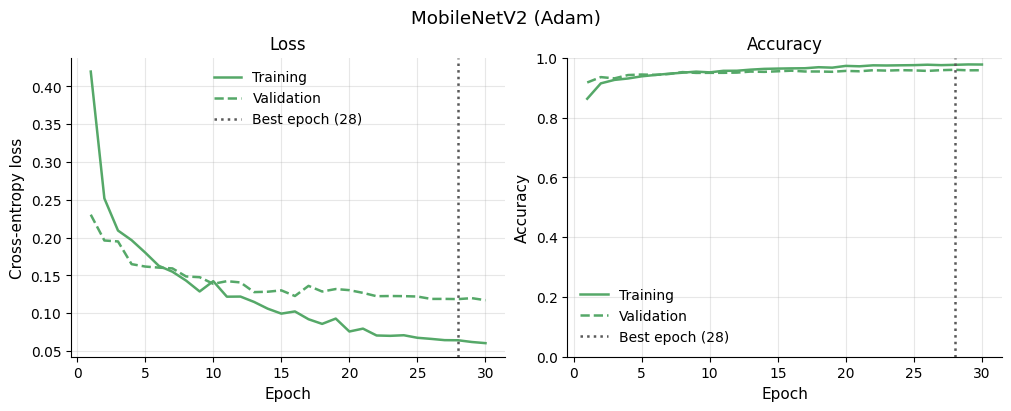

In [13]:
plot_loss_curves(histories["mobilenet_v2"])

In [14]:
test_results["mobilenet_v2"] = evaluate_on_test("mobilenet_v2", "mobilenet_v2_adam", loaders,
                                                data.class_names)

Test accuracy 0.9538 | macro precision 0.9523 | macro recall 0.9516 | 4,050 images


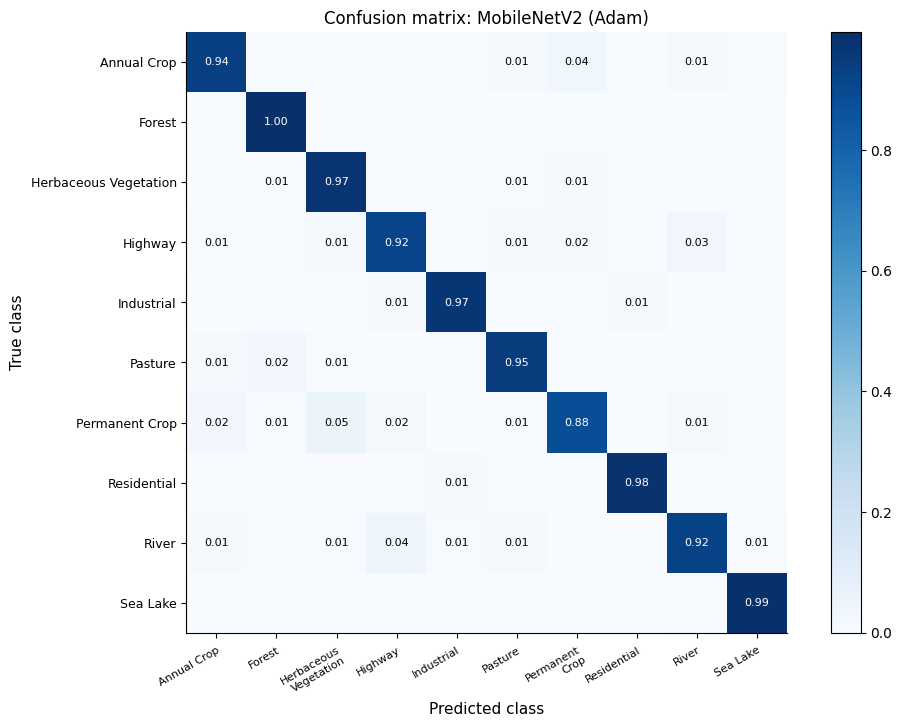

In [15]:
plot_confusion_matrix(test_results["mobilenet_v2"], "MobileNetV2 (Adam)")

## 2. SqueezeNet 1.1

In [16]:
model = build_model("squeezenet1_1")
print(f"{count_parameters(model):,} trainable of {count_parameters(model, trainable_only=False):,} "
      f"parameters | {model_size_kb(model) / 1024:.2f} MB")

Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to data/torch_hub/checkpoints/squeezenet1_1-b8a52dc0.pth


  0%|          | 0.00/4.73M [00:00<?, ?B/s]

100%|██████████| 4.73M/4.73M [00:00<00:00, 177MB/s]

391,306 trainable of 727,626 parameters | 2.79 MB


In [17]:
histories["squeezenet1_1"] = train(
    model, "squeezenet1_1", "adam", "squeezenet1_1_adam", loaders,
    backbone_lr_scale=PRETRAINED_SETTINGS["squeezenet1_1"]["backbone_lr_scale"],
)

epoch  1/30  train loss 0.4943  acc 0.8420  |  val loss 0.2845  acc 0.9052  |    8.5 s  best


epoch  2/30  train loss 0.2815  acc 0.9043  |  val loss 0.2483  acc 0.9101  |    8.6 s  best


epoch  3/30  train loss 0.2526  acc 0.9140  |  val loss 0.2371  acc 0.9232  |    8.5 s  best


epoch  4/30  train loss 0.2280  acc 0.9225  |  val loss 0.2381  acc 0.9180  |    8.5 s


epoch  5/30  train loss 0.2208  acc 0.9251  |  val loss 0.2035  acc 0.9242  |    8.5 s  best


...

epoch 26/30  train loss 0.1086  acc 0.9616  |  val loss 0.1629  acc 0.9432  |    8.4 s


epoch 27/30  train loss 0.1063  acc 0.9626  |  val loss 0.1650  acc 0.9444  |    8.4 s  best


epoch 28/30  train loss 0.1058  acc 0.9637  |  val loss 0.1636  acc 0.9425  |    8.4 s


epoch 29/30  train loss 0.1007  acc 0.9642  |  val loss 0.1642  acc 0.9442  |    8.5 s


epoch 30/30  train loss 0.1033  acc 0.9631  |  val loss 0.1631  acc 0.9440  |    8.5 s
Best validation accuracy 0.9444 at epoch 27; 8.5 s per epoch on cuda:0 (Tesla T4)


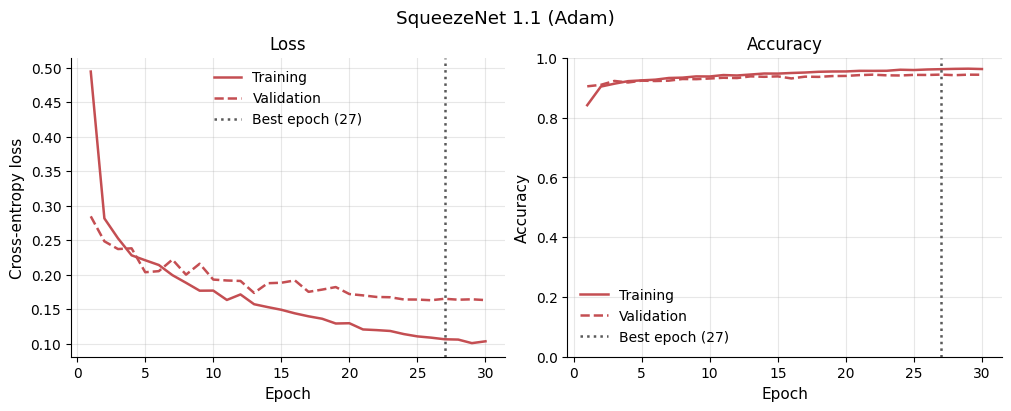

In [18]:
plot_loss_curves(histories["squeezenet1_1"])

In [19]:
test_results["squeezenet1_1"] = evaluate_on_test("squeezenet1_1", "squeezenet1_1_adam", loaders,
                                                 data.class_names)

Test accuracy 0.9422 | macro precision 0.9399 | macro recall 0.9392 | 4,050 images


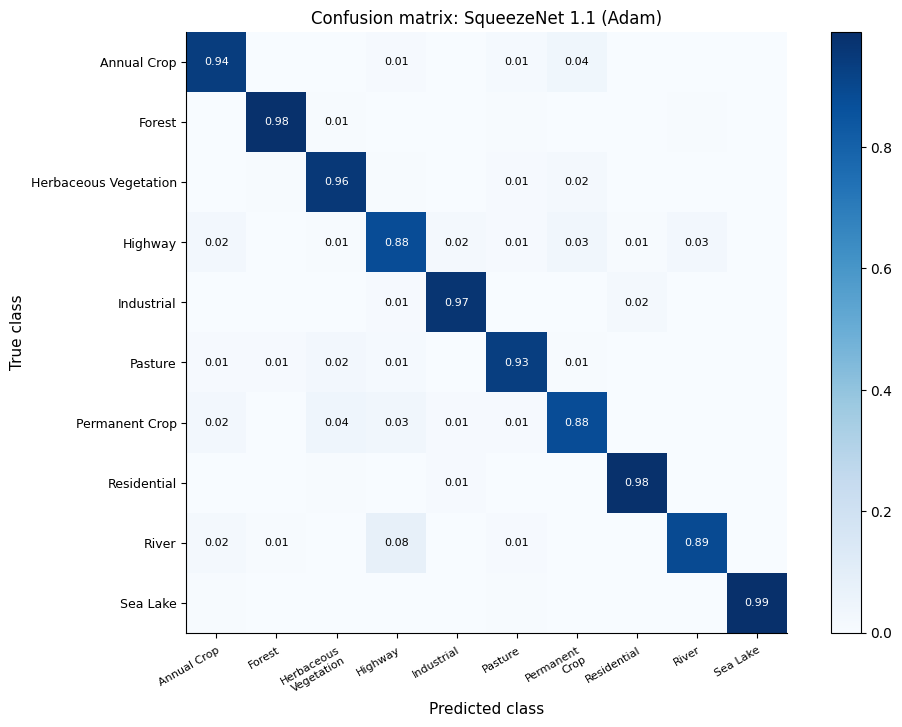

In [20]:
plot_confusion_matrix(test_results["squeezenet1_1"], "SqueezeNet 1.1 (Adam)")